# Marketing Mix Model for a Diabetes Brand

**Question:** A brand team spends about $236M a year across six channels. What
does each channel return, where should the next dollar go, and how sure can we be?

**Data:** a simulated brand (see `simulate.py`) with weekly new prescriptions
(NRx) and spend for ten US regions over 156 weeks. No company publishes weekly
spend by channel, so marketing mix work cannot be shown on public data. The
benefit of simulation is that the true return of every channel is known, so
each method can be graded against the answer.

**Method:**
1. A naive regression of NRx on spend, to show why it misleads.
2. A Bayesian marketing mix model (MMM) with carry-over and diminishing
   returns, fitted with the No-U-Turn Sampler.
3. Validation: convergence checks, an out-of-time forecast and comparison
   with the true ROI.
4. Calibration with three geo lift tests (experiments) to pin down the channels
   the observational data cannot separate.
5. Budget reallocation under uncertainty, checked against the true response.

**Terms:**
- **Adstock (carry-over):** part of this week's promotion keeps working in
  later weeks. Geometric adstock keeps a fixed share, the decay rate, each week.
- **Saturation:** diminishing returns, so each extra dollar adds less than the last.
- **ROI:** incremental net revenue per dollar spent. 1.0 means the channel pays back.
- **Marginal ROI (mROI):** the return on the next dollar, which is what budget
  decisions should use. It is lower than average ROI whenever a channel is saturating.
- **Credible interval:** the range that contains the true value with a stated
  probability, given the model and data.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import arviz as az
from scipy.optimize import minimize

warnings.filterwarnings("ignore")
HERE = Path.cwd() if Path.cwd().name.startswith("06-") else Path("06-marketing-mix-model")
sys.path.insert(0, str(HERE.parent))
sys.path.insert(0, str(HERE))
from common import style  # noqa: E402
import mmm  # noqa: E402
from simulate import CHANNELS, VALUE_PER_NRX, simulate, true_response  # noqa: E402

style.apply()
FIG, TAB = HERE / "outputs" / "figures", HERE / "outputs" / "tables"
TAB.mkdir(parents=True, exist_ok=True)
SRC = "Simulated brand data (simulate.py); illustrative economics of $3,000 net revenue per NRx"
CH = list(CHANNELS)

df, truth = simulate()
d = mmm.design(df, CH)
weeks = pd.DatetimeIndex(d["weeks"])
nat = df.groupby("week").agg(nrx=("nrx", "sum"), **{c: (f"spend::{c}", "sum") for c in CH})
annual_spend = nat[CH].sum() / 3
print(f"{len(df):,} region-weeks; national NRx {nat['nrx'].mean():,.0f} a week; "
      f"annual spend ${annual_spend.sum() / 1e6:,.0f}M")
annual_spend.div(1e6).round(1).rename("annual spend ($M)").to_frame()

1,560 region-weeks; national NRx 11,729 a week; annual spend $237M


,annual spend ($M)
Field rep details,78.0
Speaker programs,13.0
HCP digital & email,10.4
DTC television,93.6
DTC social & video,26.0
Paid search,15.7


## 1. The brand's three years

Demand dips every January to March, when patients' deductibles reset and
coverage is re-verified. It falls when a competitor launches (week 70) and
rises after a formulary win at a large PBM (week 105). TV runs in flights of
six to eight weeks; the other channels are always on.

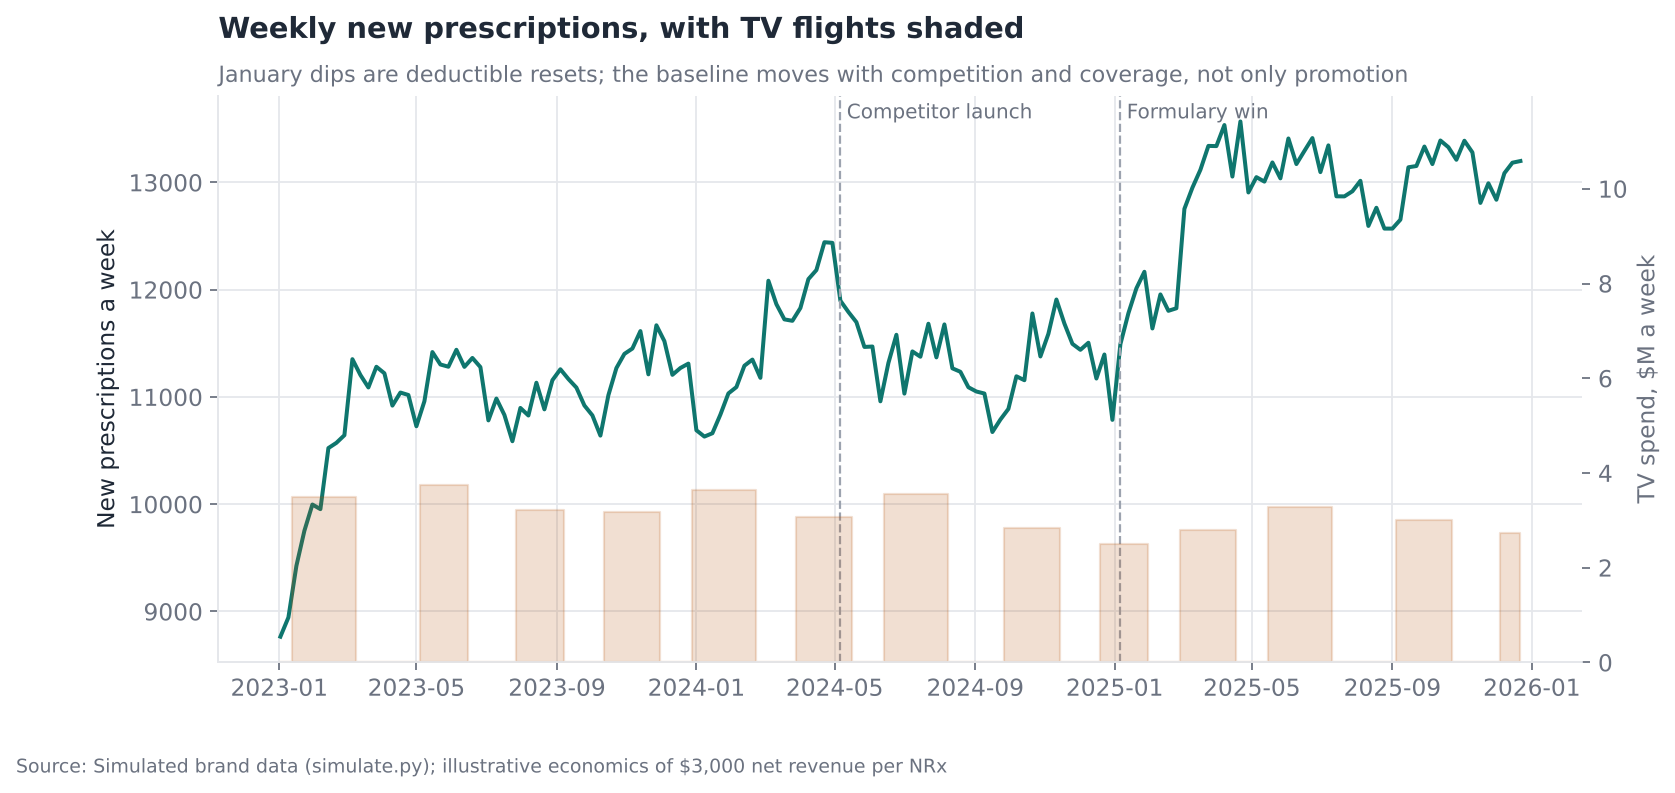

In [2]:
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.plot(weeks, nat["nrx"], color=style.ACCENT, lw=1.8, label="National NRx")
ax2 = ax.twinx()
ax2.fill_between(weeks, 0, nat["DTC television"] / 1e6, color=style.ACCENT_2, alpha=0.18, step="mid", label="TV spend")
ax2.set_ylim(0, nat["DTC television"].max() / 1e6 * 3.2)
ax2.set_ylabel("TV spend, $M a week", color=style.MUTED)
ax2.grid(False)
for wk, lab in [(70, "Competitor launch"), (105, "Formulary win")]:
    ax.axvline(weeks[wk], color=style.NEUTRAL, ls="--", lw=1)
    ax.text(weeks[wk], ax.get_ylim()[1] * 0.995, f" {lab}", color=style.MUTED, fontsize=9, va="top")
ax.set_ylabel("New prescriptions a week")
ax.set_title("Weekly new prescriptions, with TV flights shaded")
style.subtitle(ax, "January dips are deductible resets; the baseline moves with competition and coverage, not only promotion")
style.source(fig, SRC)
style.save(fig, FIG / "01_weekly_nrx_and_tv.png")

## 2. The naive approach: regress sales on spend

Ordinary least squares (OLS) on this week's spend, with the same seasonality
and event controls but no carry-over, no saturation and no priors. This is
what a quick spreadsheet regression does.

In [3]:
X_cols = []
rows = []
for r_i, reg in enumerate(d["regions"]):
    for t_i in range(len(weeks)):
        rows.append([d["y_norm"][r_i, t_i]] + list(d["xlag"][r_i, t_i, :, 0]) + list(d["four"][t_i]) +
                    [d["q1"][t_i], d["t"][t_i]] + list(d["events"][t_i]) + [1.0 if j == r_i else 0.0 for j in range(len(d["regions"]))])
M = np.array(rows)
yv, Xv = M[:, 0], M[:, 1:]
coef, *_ = np.linalg.lstsq(Xv, yv, rcond=None)
ols_contrib = np.array([(coef[i] * d["xlag"][:, :, i, 0] * d["share"][:, None] * d["ybar"]).sum() for i in range(len(CH))])
ols_roi = ols_contrib * VALUE_PER_NRX / d["spend"].sum(axis=(0, 1))
pd.DataFrame({"true ROI": truth["true_roi"].to_numpy(), "naive OLS ROI": ols_roi}, index=CH).round(2)

,true ROI,naive OLS ROI
Field rep details,1.37,0.54
Speaker programs,1.79,0.07
HCP digital & email,2.95,-2.31
DTC television,0.69,0.21
DTC social & video,1.31,2.64
Paid search,2.11,1.09


The naive model gets every large channel badly wrong. It puts the field
force at well under half its true return and TV at under a third, and it
gives HCP digital a *negative* return, which no one would believe. Ignoring
carry-over hands TV's lagged effect to whatever channel happens to be on in
the following weeks, and the model has no way to say how sure it is.

## 3. The Bayesian MMM

The model (`mmm.py`) learns, for each channel, a decay rate (carry-over over
eight weeks), a saturation curve and an effect size. Regions share the
channel curves but have their own baseline. Priors are weakly informative:
decay rates are centred on 0.5, and no channel is allowed a negative effect.

In [4]:
idata = mmm.fit(mmm.build(d), draws=1000, tune=1500)
summ = az.summary(idata, var_names=["decay", "lam", "beta", "sigma"])
diverging = int(idata.sample_stats["diverging"].sum())
diag = pd.DataFrame({
    "max r_hat": [float(summ["r_hat"].max())],
    "min bulk ESS": [float(summ["ess_bulk"].min())],
    "divergent transitions": [diverging],
    "draws": [int(mmm.posterior(idata).sizes["s"])],
})
diag

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 2 jobs)


NUTS: [decay, lam, beta, baseline_mu, baseline_sd, baseline, trend, fourier, q1_reset, events, sigma]


Sampling 4 chains for 1_500 tune and 1_000 draw iterations (6_000 + 4_000 draws total) took 444 seconds.


There were 9 divergences after tuning. Increase `target_accept` or reparameterize.


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


,max r_hat,min bulk ESS,divergent transitions,draws
0,1.003646,1463.215502,9,4000


**Reading the diagnostics:** r_hat compares the four independent chains;
values at or below 1.01 mean they agree. ESS (effective sample size) is how
many independent draws the correlated chain is worth; a few hundred is enough
for stable intervals. A handful of divergent transitions out of 4,000 draws is
a warning to watch rather than a failure.

In [5]:
pred, media_draws = mmm.predict(idata, d)
pred_nat = pred.sum(axis=1)  # (S, T)
fit_mean = pred_nat.mean(axis=0)
mape_in = float(np.mean(np.abs(fit_mean - nat["nrx"].to_numpy()) / nat["nrx"].to_numpy()))
r2_in = 1 - np.sum((fit_mean - nat["nrx"]) ** 2) / np.sum((nat["nrx"] - nat["nrx"].mean()) ** 2)
print(f"In-sample: R² {r2_in:.3f}, MAPE {mape_in:.1%}")

In-sample: R² 0.982, MAPE 0.9%


### Out-of-time check

Refit on the first 143 weeks only and forecast the last 13, which the model
never saw. This is the honest test of whether the structure generalises.

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 2 jobs)


NUTS: [decay, lam, beta, baseline_mu, baseline_sd, baseline, trend, fourier, q1_reset, events, sigma]


Sampling 4 chains for 1_000 tune and 600 draw iterations (4_000 + 2_400 draws total) took 265 seconds.


There were 3 divergences after tuning. Increase `target_accept` or reparameterize.


The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


Holdout (last 13 weeks): MAPE 0.7%; 100% of weeks inside the 90% interval


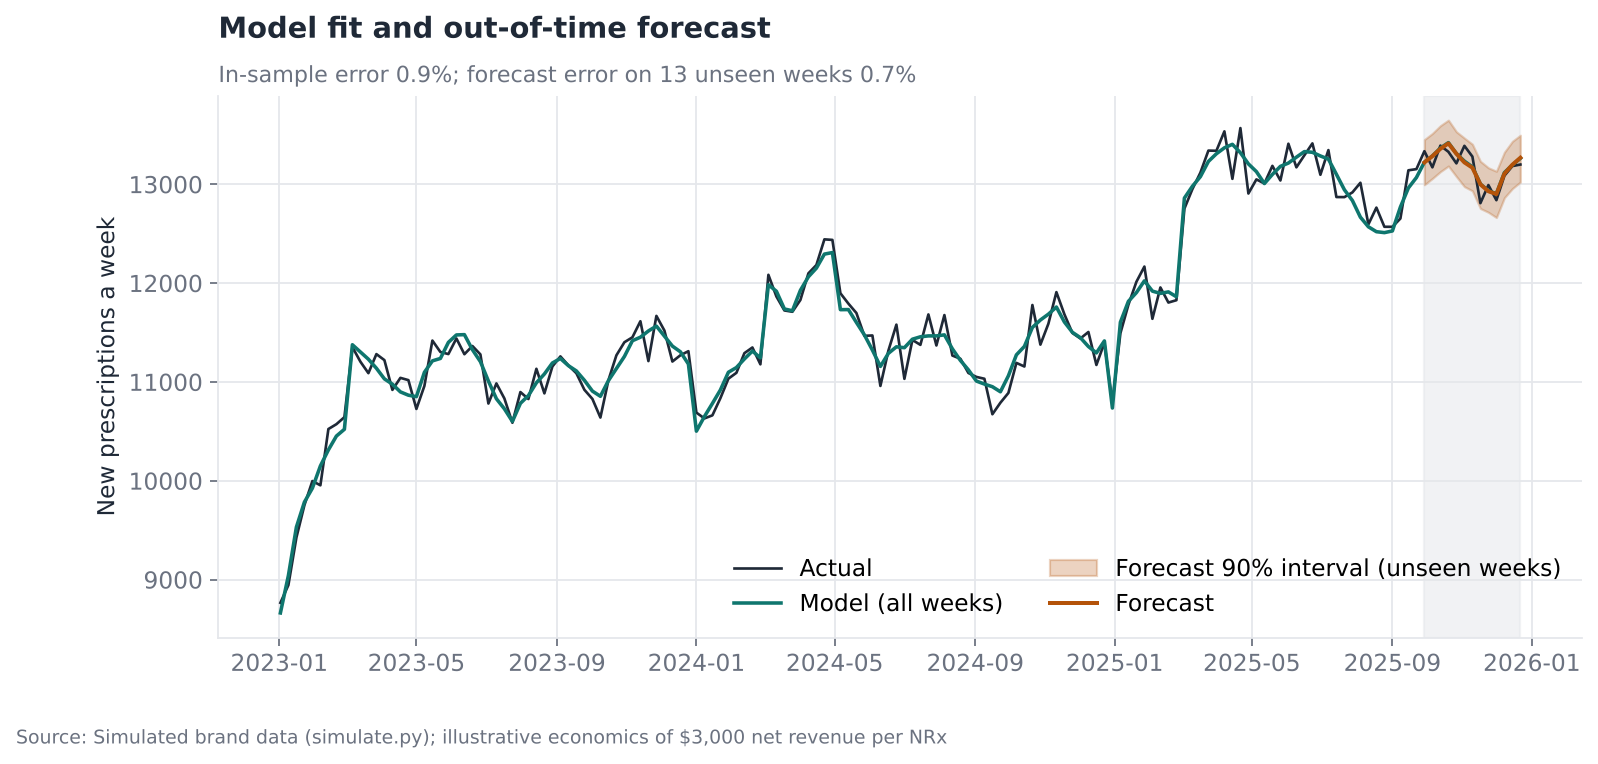

In [6]:
HOLD = 13
idata_h = mmm.fit(mmm.build(d, train_weeks=len(weeks) - HOLD), draws=600, tune=1000)
pred_h, _ = mmm.predict(idata_h, d)
sig_h = mmm.posterior(idata_h, 800)["sigma"].values  # observation noise, in normalised units
noise_sd = sig_h * np.sqrt(np.sum((d["share"] * d["ybar"]) ** 2))  # one value per draw, national scale
ph = pred_h.sum(axis=1)[:, -HOLD:] + np.random.default_rng(1).normal(0, 1, (len(sig_h), HOLD)) * noise_sd[:, None]
actual_h = nat["nrx"].to_numpy()[-HOLD:]
mape_out = float(np.mean(np.abs(ph.mean(axis=0) - actual_h) / actual_h))
lo, hi = np.percentile(ph, [5, 95], axis=0)
coverage = float(np.mean((actual_h >= lo) & (actual_h <= hi)))
print(f"Holdout (last {HOLD} weeks): MAPE {mape_out:.1%}; {coverage:.0%} of weeks inside the 90% interval")

fig, ax = plt.subplots(figsize=(11, 4.4))
ax.plot(weeks, nat["nrx"], color=style.INK, lw=1.2, label="Actual")
ax.plot(weeks, fit_mean, color=style.ACCENT, lw=1.6, label="Model (all weeks)")
ax.fill_between(weeks[-HOLD:], lo, hi, color=style.ACCENT_2, alpha=0.25, label="Forecast 90% interval (unseen weeks)")
ax.plot(weeks[-HOLD:], ph.mean(axis=0), color=style.ACCENT_2, lw=1.8, label="Forecast")
ax.axvspan(weeks[-HOLD], weeks[-1], color=style.GRID, alpha=0.5, zorder=0)
ax.set_ylabel("New prescriptions a week")
ax.set_title("Model fit and out-of-time forecast")
style.subtitle(ax, f"In-sample error {mape_in:.1%}; forecast error on 13 unseen weeks {mape_out:.1%}")
ax.legend(loc="lower right", ncol=2)
style.source(fig, SRC)
style.save(fig, FIG / "02_fit_and_holdout.png")

## 4. What drives the brand: decomposition

Most new prescriptions would happen with no promotion at all. Promotion adds
roughly a sixth, and the field force is the largest single piece.

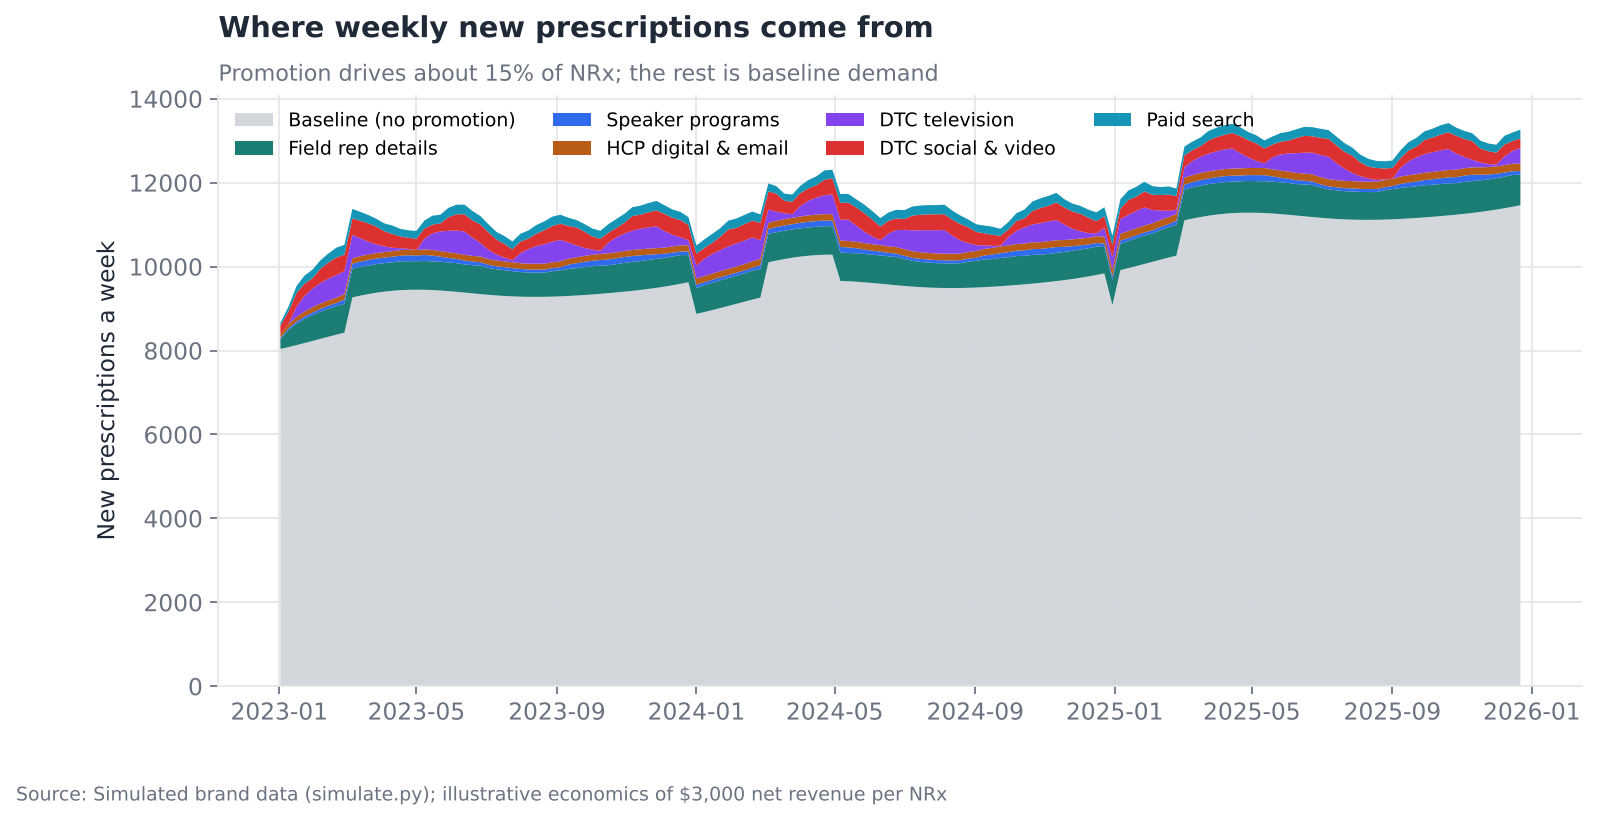

In [7]:
media_nat = media_draws.sum(axis=1).mean(axis=0)  # (T, C)
base_nat = fit_mean - media_nat.sum(axis=1)
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.stackplot(weeks, base_nat, *[media_nat[:, i] for i in range(len(CH))],
             labels=["Baseline (no promotion)"] + CH,
             colors=["#D1D5DB"] + style.PALETTE[: len(CH)], alpha=0.95)
ax.set_ylabel("New prescriptions a week")
ax.set_title("Where weekly new prescriptions come from")
style.subtitle(ax, f"Promotion drives about {media_nat.sum() / fit_mean.sum():.0%} of NRx; the rest is baseline demand")
ax.legend(loc="upper left", ncol=4, fontsize=8.5)
style.source(fig, SRC)
style.save(fig, FIG / "03_decomposition.png")

## 5. ROI by channel, checked against the truth

In [8]:
spend_tot = d["spend"].sum(axis=(0, 1))


def roi_draws(idata_) -> np.ndarray:
    c = mmm.posterior(idata_)["contribution_nrx"].values
    return c * VALUE_PER_NRX / spend_tot[:, None]


roi_u = roi_draws(idata)
roi_tab = pd.DataFrame({
    "channel": CH, "annual spend ($M)": (spend_tot / 3 / 1e6).round(1),
    "true ROI": truth["true_roi"].round(2).to_numpy(),
    "MMM ROI": roi_u.mean(axis=1).round(2),
    "90% low": np.percentile(roi_u, 5, axis=1).round(2), "90% high": np.percentile(roi_u, 95, axis=1).round(2),
    "naive OLS ROI": ols_roi.round(2),
})
roi_tab["truth inside interval"] = (roi_tab["true ROI"] >= roi_tab["90% low"]) & (roi_tab["true ROI"] <= roi_tab["90% high"])
roi_tab.to_csv(TAB / "roi_uncalibrated.csv", index=False)
roi_tab

,channel,annual spend ($M),true ROI,MMM ROI,90% low,90% high,naive OLS ROI,truth inside interval
0,Field rep details,78.0,1.37,1.35,0.71,2.00,0.54,True
1,Speaker programs,13.0,1.79,1.19,0.07,3.66,0.07,True
2,HCP digital & email,10.4,2.95,2.45,0.11,8.55,-2.31,True
3,DTC television,93.6,0.69,0.53,0.39,0.68,0.21,False
4,DTC social & video,26.0,1.31,2.01,0.96,3.27,2.64,True
5,Paid search,15.7,2.11,2.02,0.22,4.76,1.09,True


The model recovers the field force almost exactly. TV is in the right range
but somewhat low, and its narrow interval just misses the truth: a first
sign of the curve-shape problem examined in section 8. The small channels
(speaker programs, HCP digital, paid search) have wide intervals: they are
under a tenth of spend each, so the data barely moves when they do. DTC social
is overstated, because its bursts follow TV flights and the model cannot fully
tell the two apart.

This is the normal state of observational MMM, and it is the reason to run
experiments.

## 6. Calibrating with lift tests

A **geo lift test** switches a channel off (or doubles it) in a few matched
regions for some weeks and compares them with control regions (the method in
project 07). It measures one channel's incremental effect directly. Here three
such tests are simulated, for TV, DTC social and paid search, each with a
measurement error of 15%. Their results enter the model as extra evidence on
those channels' ROI; nothing else changes.

In [9]:
rng = np.random.default_rng(42)
lifts = []
for ch in ["DTC television", "DTC social & video", "Paid search"]:
    true_roi = float(truth.set_index("channel").loc[ch, "true_roi"])
    measured = true_roi * (1 + rng.normal(0, 0.10))
    lifts.append({"channel": ch, "roi": measured, "se": 0.15 * true_roi, "value": VALUE_PER_NRX})
pd.DataFrame(lifts)[["channel", "roi", "se"]].round(2).rename(columns={"roi": "measured ROI", "se": "standard error"})

,channel,measured ROI,standard error
0,DTC television,0.71,0.10
1,DTC social & video,1.17,0.20
2,Paid search,2.27,0.32


Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 2 jobs)


NUTS: [decay, lam, beta, baseline_mu, baseline_sd, baseline, trend, fourier, q1_reset, events, sigma]


Sampling 4 chains for 1_500 tune and 1_000 draw iterations (6_000 + 4_000 draws total) took 406 seconds.


There were 18 divergences after tuning. Increase `target_accept` or reparameterize.


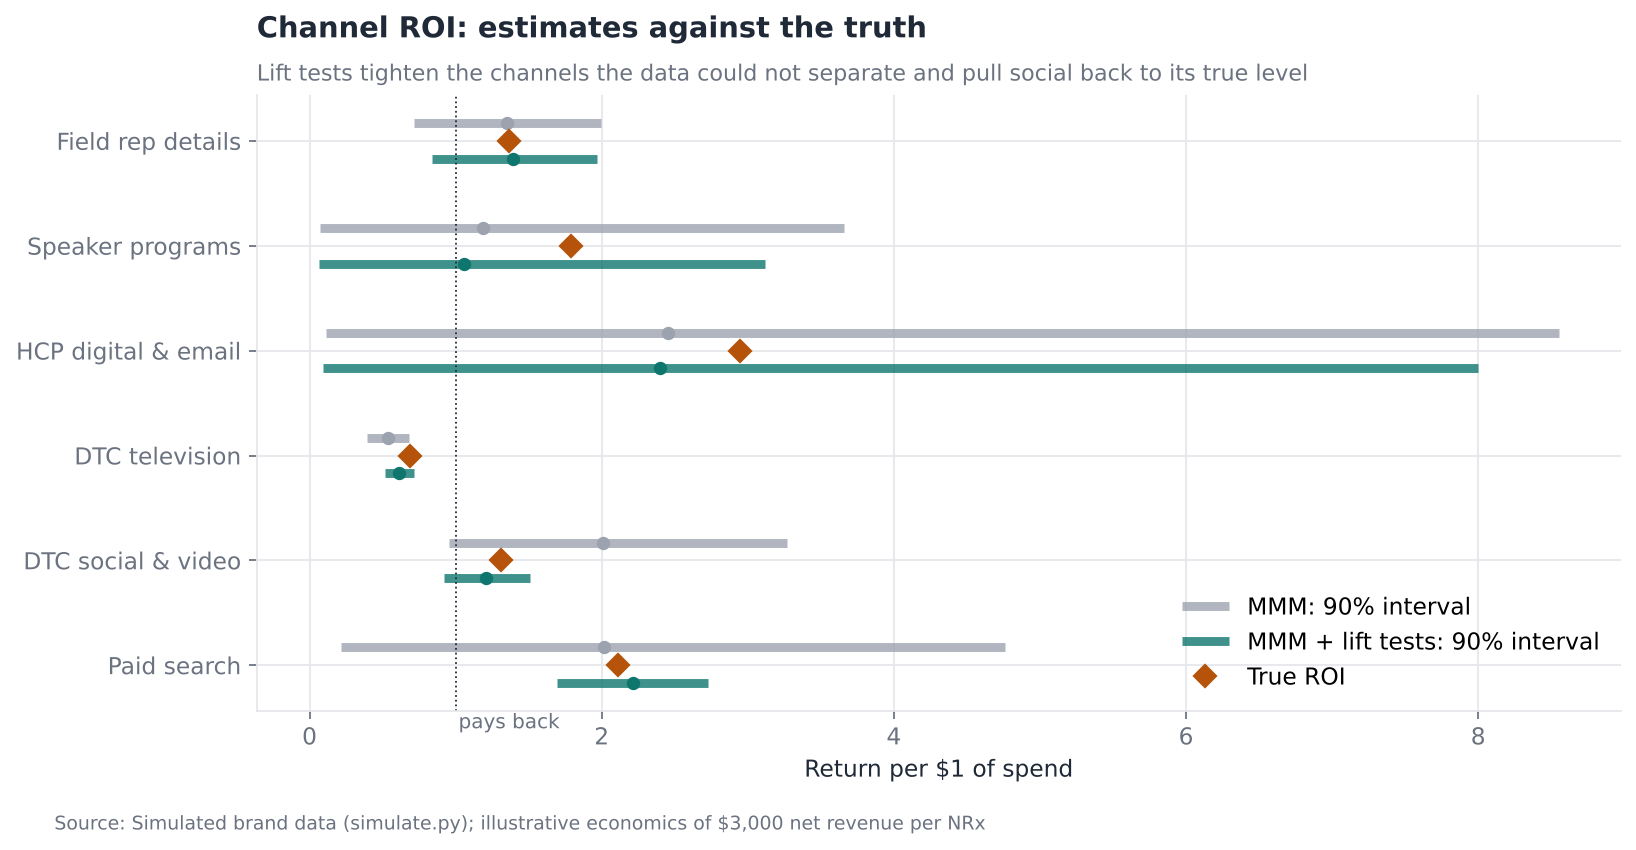

,channel,true ROI,calibrated ROI,90% low,90% high,interval width before,interval width after
0,Field rep details,1.37,1.39,0.84,1.97,1.28,1.13
1,Speaker programs,1.79,1.06,0.06,3.12,3.59,3.06
2,HCP digital & email,2.95,2.40,0.09,8.00,8.44,7.90
3,DTC television,0.69,0.61,0.52,0.72,0.28,0.20
4,DTC social & video,1.31,1.21,0.92,1.51,2.31,0.59
5,Paid search,2.11,2.21,1.70,2.73,4.54,1.03


In [10]:
import pymc as pm  # noqa: E402

model_cal = mmm.build(d)
with model_cal:
    for lt in lifts:
        ci = CH.index(lt["channel"])
        roi_c = model_cal["contribution_nrx"][ci] * lt["value"] / spend_tot[ci]
        pm.Normal(f"lift_{ci}", roi_c, lt["se"], observed=lt["roi"])
idata_c = mmm.fit(model_cal, draws=1000, tune=1500, seed=11)
roi_c = roi_draws(idata_c)

fig, ax = plt.subplots(figsize=(11, 5))
ypos = np.arange(len(CH))
for k, (r, lab, col, off) in enumerate([(roi_u, "MMM", style.NEUTRAL, -0.17), (roi_c, "MMM + lift tests", style.ACCENT, 0.17)]):
    lo_, hi_ = np.percentile(r, [5, 95], axis=1)
    ax.hlines(ypos + off, lo_, hi_, color=col, lw=4, alpha=0.8, label=f"{lab}: 90% interval")
    ax.plot(r.mean(axis=1), ypos + off, "o", color=col, ms=5)
ax.plot(truth["true_roi"], ypos, "D", color=style.ACCENT_2, ms=7, label="True ROI")
ax.axvline(1, color=style.INK, lw=0.8, ls=":")
ax.text(1.02, len(CH) - 0.4, "pays back", color=style.MUTED, fontsize=9)
ax.set_yticks(ypos, CH)
ax.invert_yaxis()
ax.set_xlabel("Return per $1 of spend")
ax.set_title("Channel ROI: estimates against the truth")
style.subtitle(ax, "Lift tests tighten the channels the data could not separate and pull social back to its true level")
ax.legend(loc="lower right")
style.source(fig, SRC)
style.save(fig, FIG / "04_roi_vs_truth.png")

roi_cal_tab = pd.DataFrame({
    "channel": CH, "true ROI": truth["true_roi"].round(2).to_numpy(),
    "calibrated ROI": roi_c.mean(axis=1).round(2),
    "90% low": np.percentile(roi_c, 5, axis=1).round(2), "90% high": np.percentile(roi_c, 95, axis=1).round(2),
    "interval width before": (np.percentile(roi_u, 95, axis=1) - np.percentile(roi_u, 5, axis=1)).round(2),
    "interval width after": (np.percentile(roi_c, 95, axis=1) - np.percentile(roi_c, 5, axis=1)).round(2),
})
roi_cal_tab.to_csv(TAB / "roi_calibrated.csv", index=False)
roi_cal_tab

## 7. Carry-over and diminishing returns

**Half-life** is how many weeks it takes for half of a week's effect to wear
off: ln(0.5) / ln(decay). TV's effect lasts longest; search is almost
immediate, as it should be for people who are already looking.

In [11]:
post = mmm.posterior(idata_c)
decay_post = post["decay"].values  # (C, S)
half_life = np.log(0.5) / np.log(np.clip(decay_post, 1e-3, 0.999))
carry = pd.DataFrame({
    "channel": CH, "true decay": truth["true_decay"].to_numpy(), "estimated decay": decay_post.mean(axis=1).round(2),
    "half-life, weeks (median)": np.median(half_life, axis=1).round(1),
    "true half-life, weeks": (np.log(0.5) / np.log(truth["true_decay"])).round(1).to_numpy(),
})
carry

,channel,true decay,estimated decay,"half-life, weeks (median)","true half-life, weeks"
0,Field rep details,0.55,0.64,1.7,1.2
1,Speaker programs,0.70,0.61,1.5,1.9
2,HCP digital & email,0.35,0.49,1.0,0.7
3,DTC television,0.80,0.75,2.4,3.1
4,DTC social & video,0.45,0.42,0.8,0.9
5,Paid search,0.15,0.57,1.3,0.4


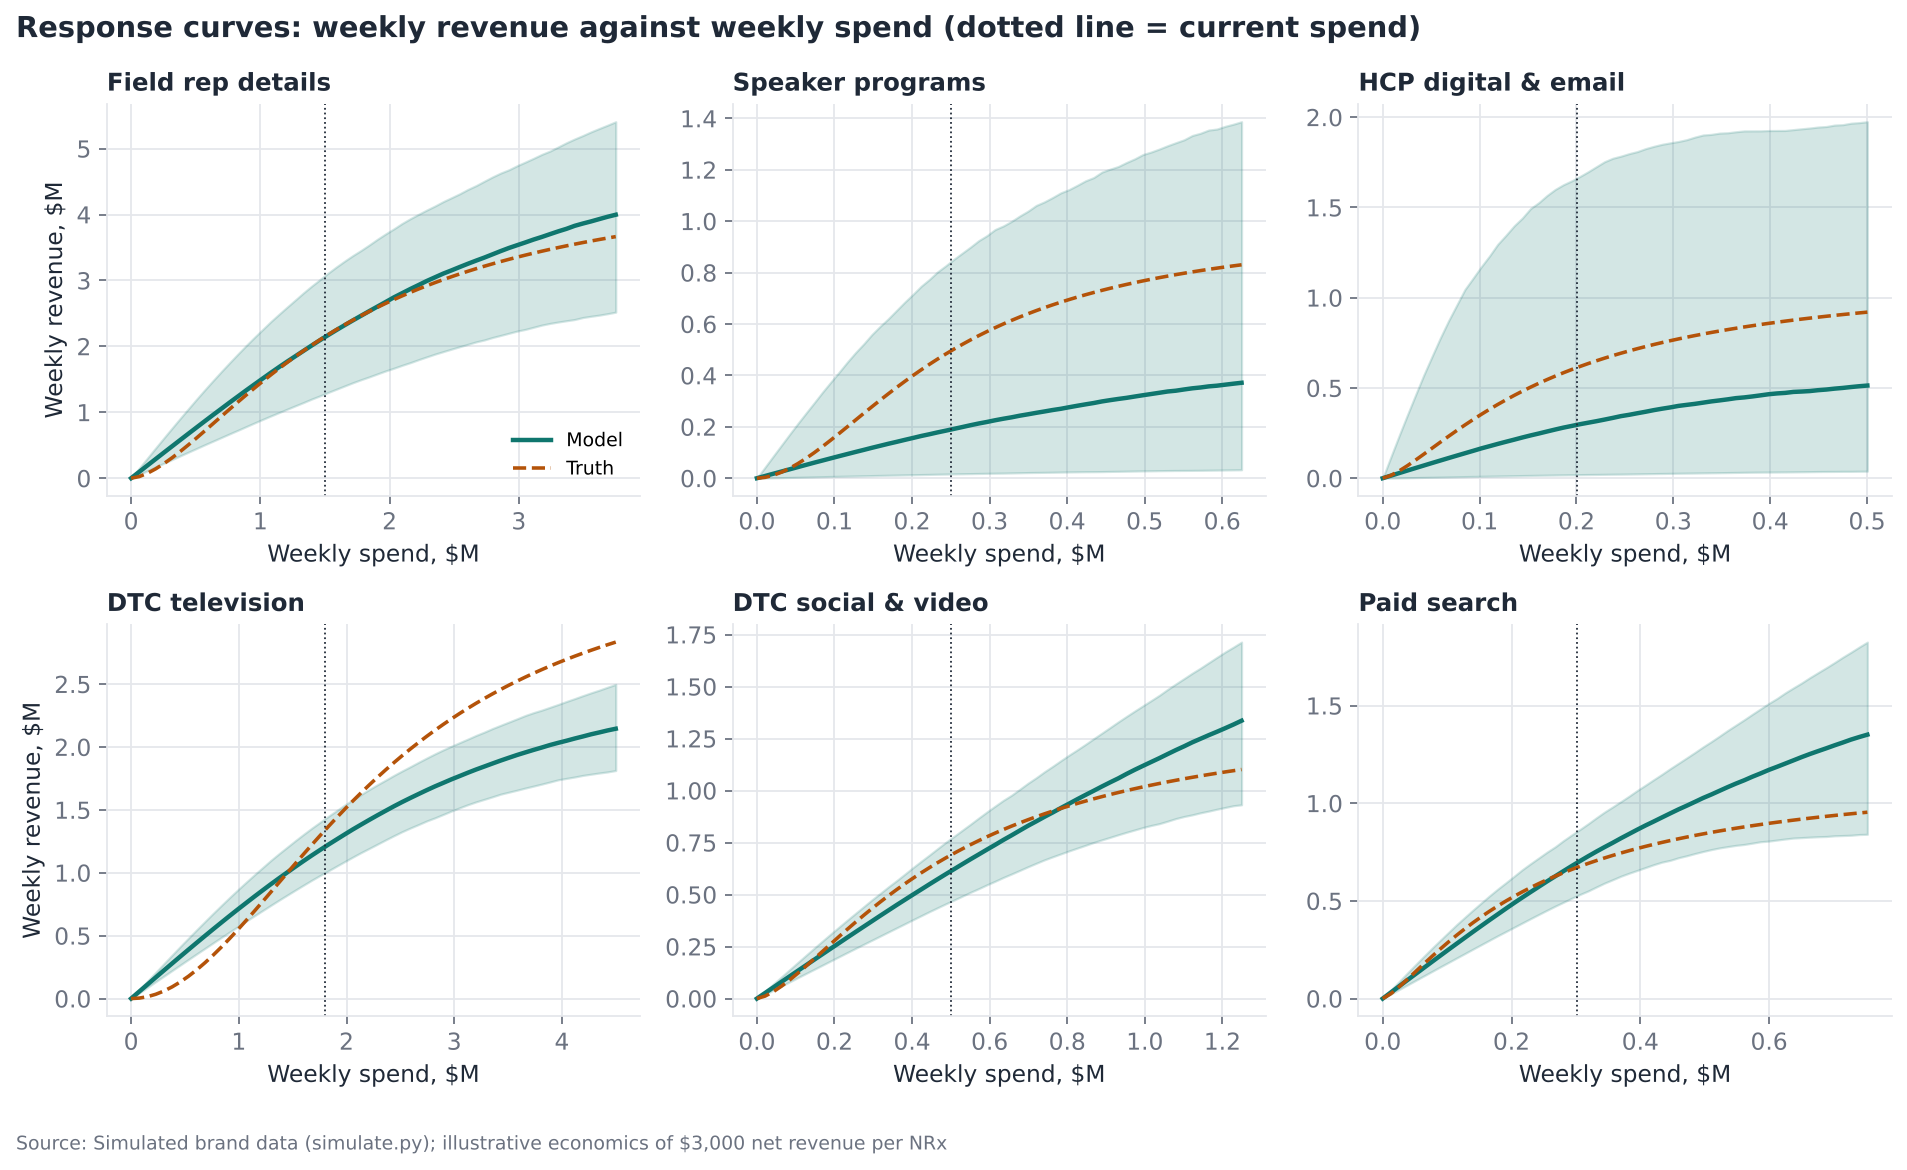

,channel,marginal ROI,90% low,90% high,true marginal ROI
0,Field rep details,1.19,0.74,1.61,1.23
1,Speaker programs,0.62,0.05,2.49,1.77
2,HCP digital & email,0.97,0.08,3.61,1.97
3,DTC television,0.55,0.47,0.63,0.93
4,DTC social & video,1.14,0.83,1.43,1.03
5,Paid search,1.98,1.12,2.56,1.23


In [12]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharey=False)
mroi_rows = []
for i, (ch, ax) in enumerate(zip(CH, axes.ravel())):
    cur = d["nat_mean"][i]
    grid = np.linspace(0, cur * 2.5, 60)
    resp = mmm.response(idata_c, d, i, grid) * VALUE_PER_NRX / 1e6  # $M revenue a week
    lo_, mid, hi_ = np.percentile(resp, [5, 50, 95], axis=0)
    ax.fill_between(grid / 1e6, lo_, hi_, color=style.ACCENT, alpha=0.18)
    ax.plot(grid / 1e6, mid, color=style.ACCENT, lw=2, label="Model")
    ax.plot(grid / 1e6, true_response(ch, grid) * VALUE_PER_NRX / 1e6, color=style.ACCENT_2, ls="--", lw=1.6, label="Truth")
    ax.axvline(cur / 1e6, color=style.INK, lw=0.8, ls=":")
    ax.set_title(ch, fontsize=11)
    ax.set_xlabel("Weekly spend, $M")
    if i % 3 == 0:
        ax.set_ylabel("Weekly revenue, $M")
    eps = cur * 0.01
    m = (mmm.response(idata_c, d, i, np.array([cur + eps])) - mmm.response(idata_c, d, i, np.array([cur]))) / eps * VALUE_PER_NRX
    true_m = (true_response(ch, np.array([cur + eps])) - true_response(ch, np.array([cur]))) / eps * VALUE_PER_NRX
    mroi_rows.append({"channel": ch, "marginal ROI": float(np.median(m)), "90% low": float(np.percentile(m, 5)),
                      "90% high": float(np.percentile(m, 95)), "true marginal ROI": float(true_m[0])})
axes[0, 0].legend(loc="lower right", fontsize=8.5)
fig.suptitle("Response curves: weekly revenue against weekly spend (dotted line = current spend)", x=0.01, ha="left",
             fontsize=13, fontweight="bold", color=style.INK)
fig.tight_layout()
style.source(fig, SRC)
style.save(fig, FIG / "05_response_curves.png")
mroi = pd.DataFrame(mroi_rows).round(2)
mroi.to_csv(TAB / "marginal_roi.csv", index=False)
mroi

Average ROI and marginal ROI tell different stories. By the model, paid
search has the best return on the next dollar and TV the worst. The last
column shows where the model is wrong at the margin: speaker programs and HCP
digital are worth far more on the next dollar than the model thinks, and TV
somewhat more. Those gaps are exactly what the optimiser below will exploit.

## 8. Reallocating the same budget

Keep the total budget fixed and move money between channels to maximise
expected revenue, averaged over all 4,000 posterior draws (so uncertain
channels are not over-funded). Limits keep the plan realistic: the field force
can move only ±20% in a year, and every other channel stays within 50–150% of
today.

In [13]:
cur = d["nat_mean"].copy()
bounds = [(cur[i] * (0.8 if ch == "Field rep details" else 0.5), cur[i] * (1.2 if ch == "Field rep details" else 1.5))
          for i, ch in enumerate(CH)]
post_c = mmm.posterior(idata_c)
lam_s, beta_s = post_c["lam"].values, post_c["beta"].values  # (C, S)


def revenue(spend_vec: np.ndarray) -> np.ndarray:
    x = spend_vec[:, None] / d["nat_mean"][:, None]
    sat = (1 - np.exp(-lam_s * x)) / (1 + np.exp(-lam_s * x))
    return (sat * beta_s).sum(axis=0) * d["ybar"] * VALUE_PER_NRX  # (S,)


res = minimize(lambda s: -revenue(s * 1e6).mean() / 1e6, cur / 1e6, method="SLSQP",
               bounds=[(a / 1e6, b / 1e6) for a, b in bounds],
               constraints=[{"type": "eq", "fun": lambda s: s.sum() - cur.sum() / 1e6}])
opt = res.x * 1e6
gain = (revenue(opt) - revenue(cur)) * 52
true_gain = sum((true_response(ch, np.array([opt[i]])) - true_response(ch, np.array([cur[i]])))[0] for i, ch in enumerate(CH)) * VALUE_PER_NRX * 52

def optimise(lo_mult: float, hi_mult: float, rep_lo: float = 0.8, rep_hi: float = 1.2) -> np.ndarray:
    bnds = [(cur[i] * (rep_lo if ch == "Field rep details" else lo_mult) / 1e6, cur[i] * (rep_hi if ch == "Field rep details" else hi_mult) / 1e6)
            for i, ch in enumerate(CH)]
    r = minimize(lambda s_: -revenue(s_ * 1e6).mean() / 1e6, cur / 1e6, method="SLSQP", bounds=bnds,
                 constraints=[{"type": "eq", "fun": lambda s_: s_.sum() - cur.sum() / 1e6}])
    return r.x * 1e6


def true_gain_of(plan_vec: np.ndarray) -> float:
    return sum((true_response(ch, np.array([plan_vec[i]])) - true_response(ch, np.array([cur[i]])))[0]
               for i, ch in enumerate(CH)) * VALUE_PER_NRX * 52


cautious = optimise(0.8, 1.2)
gain_c = (revenue(cautious) - revenue(cur)) * 52
true_gain_c = true_gain_of(cautious)

# The ceiling: the best reallocation within the bold limits if the true response curves were known
ro = minimize(lambda s_: -true_gain_of(s_ * 1e6) / 1e6, cur / 1e6, method="SLSQP", bounds=[(a / 1e6, b / 1e6) for a, b in bounds],
              constraints=[{"type": "eq", "fun": lambda s_: s_.sum() - cur.sum() / 1e6}])
oracle = ro.x * 1e6
true_gain_o = true_gain_of(oracle)
plans = pd.DataFrame({
    "plan": ["Bold (channels 50-150%)", "Cautious (all channels 80-120%)", "Best possible (true curves, bold limits)"],
    "model: expected gain ($M/yr)": [np.median(gain) / 1e6, np.median(gain_c) / 1e6, np.nan],
    "model: 90% low": [np.percentile(gain, 5) / 1e6, np.percentile(gain_c, 5) / 1e6, np.nan],
    "model: 90% high": [np.percentile(gain, 95) / 1e6, np.percentile(gain_c, 95) / 1e6, np.nan],
    "TRUE gain ($M/yr)": [true_gain / 1e6, true_gain_c / 1e6, true_gain_o / 1e6],
}).round(1)
plans.to_csv(TAB / "plans_vs_truth.csv", index=False)
plan = pd.DataFrame({"channel": CH, "current annual ($M)": cur * 52 / 1e6, "recommended annual ($M)": opt * 52 / 1e6,
                     "cautious annual ($M)": cautious * 52 / 1e6, "best possible annual ($M)": oracle * 52 / 1e6})
plan["change"] = plan["recommended annual ($M)"] / plan["current annual ($M)"] - 1
plan["cautious change"] = plan["cautious annual ($M)"] / plan["current annual ($M)"] - 1
plan.to_csv(TAB / "budget_plan.csv", index=False)
print(f"Expected extra revenue a year: ${np.median(gain) / 1e6:,.1f}M "
      f"(90% interval ${np.percentile(gain, 5) / 1e6:,.1f}M to ${np.percentile(gain, 95) / 1e6:,.1f}M); "
      f"under the true response: ${true_gain / 1e6:,.1f}M")
display_plans = (plan.round(2), plans)
display_plans

Expected extra revenue a year: $25.3M (90% interval $11.1M to $40.3M); under the true response: $5.6M


(               channel  current annual ($M)  recommended annual ($M)  \
 0    Field rep details                78.00                    93.60   
 1     Speaker programs                13.00                    18.17   
 2  HCP digital & email                10.41                    15.61   
 3       DTC television                93.60                    46.80   
 4   DTC social & video                25.99                    38.98   
 5          Paid search                15.65                    23.48   
 
    cautious annual ($M)  best possible annual ($M)  change  cautious change  
 0                 90.16                      93.60     0.2             0.16  
 1                 10.40                      19.50     0.4            -0.20  
 2                 11.94                      15.61     0.5             0.15  
 3                 74.88                      62.05    -0.5            -0.20  
 4                 30.49                      27.20     0.5             0.17  
 5           

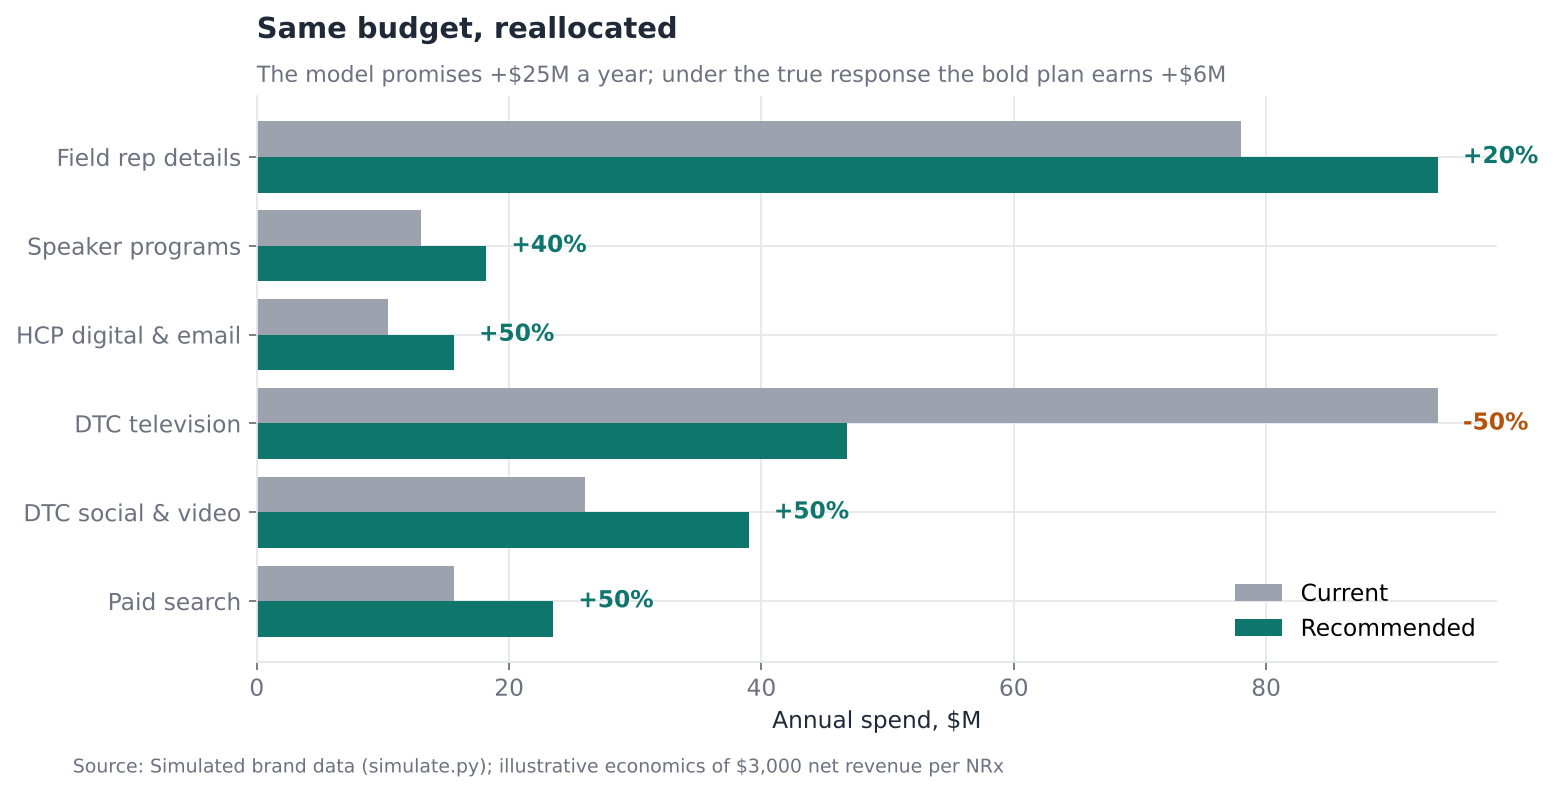

In [14]:
fig, ax = plt.subplots(figsize=(10, 4.6))
yp = np.arange(len(CH))
ax.barh(yp - 0.2, plan["current annual ($M)"], 0.4, color=style.NEUTRAL, label="Current")
ax.barh(yp + 0.2, plan["recommended annual ($M)"], 0.4, color=style.ACCENT, label="Recommended")
for i, r in plan.iterrows():
    ax.text(max(r["current annual ($M)"], r["recommended annual ($M)"]) + 2, i, f"{r['change']:+.0%}", va="center",
            color=style.ACCENT if r["change"] > 0 else style.ACCENT_2, fontweight="bold")
ax.set_yticks(yp, CH)
ax.invert_yaxis()
ax.set_xlabel("Annual spend, $M")
ax.set_title("Same budget, reallocated")
style.subtitle(ax, f"The model promises +${np.median(gain) / 1e6:,.0f}M a year; under the true response the bold plan earns +${true_gain / 1e6:,.0f}M")
ax.legend(loc="lower right")
style.source(fig, SRC)
style.save(fig, FIG / "06_budget_reallocation.png")

**The most important result in this project.** Both plans make money under
the true response, but far less than the model promised, and neither true
gain falls inside the model's 90% interval. The optimiser's promised gain is
mostly the model's own error, found and exploited.

Two errors drive it, both visible in the marginal ROI table above:

- **TV.** Its true response is S-shaped (it needs a minimum weight before it
  works), and the model's saturation curve cannot bend that way. The model
  puts TV's next dollar well below its true value, so both plans cut TV.
- **Speaker programs.** They are a small budget that moves little, so the
  data cannot pin down their return. The model's marginal ROI is a fraction of
  the true one, and the cautious plan cuts them, which is the wrong direction.

The "best possible" row shows what perfect knowledge of the curves would earn
within the same limits. Against that ceiling the bold plan does reasonably:
most of its moves point the right way, and it earns a good share of what was
available. What it gets wrong is the *size* of the prize, which it overstates
several times over. The cautious plan is not safer in proportion: it keeps the
same wrong directions and simply moves less.

The practical rule: treat an MMM budget recommendation as a list of
hypotheses, ranked by expected value. Test the largest moves, and any move in
a channel whose interval is wide, with a geo experiment (project 07) before
making them, feed the result back as a lift-test calibration, and refit as
the new spend levels produce data the model has not seen.

## 9. Summary

In [15]:
summary = {
    "annual_spend_musd": round(float(annual_spend.sum() / 1e6), 1),
    "promotion_share_of_nrx": round(float(media_nat.sum() / fit_mean.sum()), 3),
    "in_sample_mape": round(mape_in, 4), "in_sample_r2": round(float(r2_in), 3),
    "holdout_mape": round(mape_out, 4), "holdout_interval_coverage": round(coverage, 2),
    "max_rhat": round(float(summ["r_hat"].max()), 3), "divergences": diverging,
    "truth_inside_90pct_uncalibrated": int(roi_tab["truth inside interval"].sum()),
    "truth_inside_90pct_calibrated": int(((roi_cal_tab["true ROI"] >= roi_cal_tab["90% low"]) & (roi_cal_tab["true ROI"] <= roi_cal_tab["90% high"])).sum()),
    "roi_calibrated": dict(zip(CH, roi_c.mean(axis=1).round(2).tolist())),
    "roi_true": dict(zip(CH, truth["true_roi"].round(2).tolist())),
    "reallocation_gain_musd_median": round(float(np.median(gain) / 1e6), 1),
    "reallocation_gain_musd_p5": round(float(np.percentile(gain, 5) / 1e6), 1),
    "reallocation_gain_musd_p95": round(float(np.percentile(gain, 95) / 1e6), 1),
    "reallocation_gain_true_musd": round(float(true_gain / 1e6), 1),
    "plan_change": dict(zip(CH, plan["change"].round(3).tolist())),
    "oracle_gain_true_musd": round(float(true_gain_o / 1e6), 1),
    "cautious_gain_musd_median": round(float(np.median(gain_c) / 1e6), 1),
    "cautious_gain_true_musd": round(float(true_gain_c / 1e6), 1),
    "cautious_plan_change": dict(zip(CH, plan["cautious change"].round(3).tolist())),
}
pd.Series(summary).to_json(TAB / "summary.json", indent=1)
summary

{'annual_spend_musd': 236.6,
 'promotion_share_of_nrx': 0.153,
 'in_sample_mape': 0.0093,
 'in_sample_r2': 0.982,
 'holdout_mape': 0.0067,
 'holdout_interval_coverage': 1.0,
 'max_rhat': 1.004,
 'divergences': 9,
 'truth_inside_90pct_uncalibrated': 5,
 'truth_inside_90pct_calibrated': 6,
 'roi_calibrated': {'Field rep details': 1.39,
  'Speaker programs': 1.06,
  'HCP digital & email': 2.4,
  'DTC television': 0.61,
  'DTC social & video': 1.21,
  'Paid search': 2.21},
 'roi_true': {'Field rep details': 1.37,
  'Speaker programs': 1.79,
  'HCP digital & email': 2.95,
  'DTC television': 0.69,
  'DTC social & video': 1.31,
  'Paid search': 2.11},
 'reallocation_gain_musd_median': 25.3,
 'reallocation_gain_musd_p5': 11.1,
 'reallocation_gain_musd_p95': 40.3,
 'reallocation_gain_true_musd': 5.6,
 'plan_change': {'Field rep details': 0.2,
  'Speaker programs': 0.398,
  'HCP digital & email': 0.5,
  'DTC television': -0.5,
  'DTC social & video': 0.5,
  'Paid search': 0.5},
 'oracle_gain_tr